# Boson Sampling and Gaussian Boson Sampling: API tour, validation and benchmarks

Every number in this notebook is computed when the notebook runs; nothing is hard-coded.
The default configuration (`FULL = False`) finishes in a few minutes on a laptop CPU.
Set `FULL = True` to run the benchmark scripts' `default` configuration instead of the small
`notebook` configuration (several minutes more).

In [1]:
import glob
import importlib.util
import json
import math
import os
import sys
import tempfile
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

import photographiq as pg
from photographiq import native
from photographiq import sampling as S

FULL = False  # True: larger benchmark sizes (slower)

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "benchmarks" / "bench_common.py").exists()
)
for sub in ("benchmarks", "benchmarks/boson_sampling", "benchmarks/gaussian_boson_sampling"):
    sys.path.insert(0, str(ROOT / sub))
import bench_boson_sampling as bbs  # noqa: E402  (found through sys.path above)
import bench_common as common  # noqa: E402
import bench_gbs as bgbs  # noqa: E402

NATIVE = "sampling" in native.components()
PIQUASSO = importlib.util.find_spec("piquasso") is not None
BACKEND = "native" if NATIVE else "python"
CONFIG = "default" if FULL else "notebook"
OUT = Path(
    tempfile.mkdtemp(prefix="pgq_bench_")
)  # live results; the scripts write to benchmarks/*/results
T0 = time.perf_counter()
print(
    f"repo root: {ROOT}\nphotographiq {pg.__version__}; native sampling kernels: {NATIVE}; Piquasso: {PIQUASSO}; config: {CONFIG}"
)

repo root: d:\Research\QML\results_1\cvqc\thesis_part_2\softwares\PhotoGraphiQ
photographiq 0.3.1; native sampling kernels: True; Piquasso: True; config: notebook


## 1 Introduction

*Boson sampling* (BS) sends $n$ single photons through an $m$-mode linear interferometer $U$
and counts photons at the outputs; output probabilities are squared moduli of matrix
**permanents**. *Gaussian boson sampling* (GBS) replaces the single photons by squeezed
(possibly displaced, lossy) Gaussian states; photon-number-resolving (PNR) probabilities are
**hafnians** / **loop hafnians**, threshold-detector (click / no-click) probabilities are
**torontonians**. All three are #P-hard in general, which is why these tasks are used as
quantum-advantage proposals and why exact simulators scale exponentially.

This notebook covers `photographiq.sampling`: its conventions, a tour of the API, numerical
validation against brute force and closed forms, and benchmarks against
[Piquasso](https://github.com/Budapest-Quantum-Computing-Group/piquasso) on identical
inputs. The benchmarks are run through the scripts in `benchmarks/boson_sampling/` and
`benchmarks/gaussian_boson_sampling/`; see `benchmarks/README.md` for the methodology.

## 2 Physics and probability definitions

**Conventions.** $\hbar = 2$, interleaved quadratures $(q_1,p_1,q_2,p_2,\dots)$, vacuum
covariance $V = I$, $a_j = (q_j + i p_j)/2$. An interferometer acts as
$a_k \to \sum_j U_{kj} a_j$, i.e. $a_j^\dagger \to \sum_k U_{kj} a_k^\dagger$.

**Boson sampling.** For input occupation $s$ and output occupation $t$
($\sum_i s_i = \sum_j t_j = n$),
$$
\langle t | W(U) | s\rangle = \frac{\operatorname{Perm}(U_{t,s})}{\sqrt{\prod_i s_i!\,\prod_j t_j!}},
\qquad
P(t\mid s) = \frac{|\operatorname{Perm}(U_{t,s})|^2}{\prod_i s_i!\,\prod_j t_j!},
$$
where $U_{t,s}$ repeats row $k$ of $U$ $t_k$ times and column $j$ $s_j$ times (the
multiplicity normalisation accounts for bunched photons), and
$\operatorname{Perm}(M) = \sum_{\pi\in S_n}\prod_i M_{i\pi(i)}$.

**Gaussian states in ladder form.** With $\xi = (a_1..a_m, a_1^\dagger..a_m^\dagger)$, mean
$\beta = \langle\xi\rangle = (\alpha, \alpha^*)$, $\alpha_j = (d_{q_j} + i d_{p_j})/2$, and
$$
\sigma_Q = \sigma + \tfrac{I}{2} = \tfrac{1}{2}\,\mathcal U (V + I)\,\mathcal U^\dagger
\quad(\text{vacuum: } \sigma_Q = I),\qquad
A = X\,(I - \sigma_Q^{-1})^*,\quad X = \begin{pmatrix}0 & I\\ I & 0\end{pmatrix},\quad
\gamma = \sigma_Q^{-1}\beta,
$$
with $\mathcal U$ the unitary map from quadratures to $\xi$ (scaled by $\sqrt2$), the
vacuum probability is
$p_0 = e^{-\beta^\dagger\sigma_Q^{-1}\beta/2}/\sqrt{\det\sigma_Q} = 2^m e^{-d^T(V+I)^{-1}d/2}/\sqrt{\det(V+I)}$.

**GBS, PNR detectors.** For the pattern $n = (n_1..n_m)$, $N = \sum n_i$:
* mixed state, no displacement: $P(n) = p_0\,\operatorname{haf}(A_{n\oplus n}) / \prod_i n_i!$ ($2N\times 2N$ hafnian),
* pure state ($A = B\oplus B^*$): $P(n) = p_0\,|\operatorname{haf}(B_n)|^2/\prod_i n_i!$ ($N\times N$),
* displaced: hafnians become loop hafnians, $\operatorname{lhaf}(A_{n\oplus n};\gamma_{n\oplus n})$ (resp. $|\operatorname{lhaf}(B_n;\gamma_n)|^2$),

where $\operatorname{haf}(A) = \sum_{\mu\in\mathrm{PMP}}\prod_{(i,j)\in\mu}A_{ij}$ sums over perfect
matchings and the loop hafnian also allows loops weighted by the diagonal / loop vector.

**GBS, threshold detectors.** With $O = I - \sigma_Q^{-1}$ and $S$ the set of clicked modes,
$$
P(S) = p_0\,\operatorname{Tor}(O_S),\qquad
\operatorname{Tor}(O) = \sum_{Z\subseteq S}(-1)^{|S|-|Z|}\frac{1}{\sqrt{\det(I - O_Z)}},
$$
with the loop torontonian $\operatorname{ltor}(O_S, \gamma^*_S)$ for displaced states. Loss
$\eta$ maps $V\to\eta V + (1-\eta) I$, $d \to \sqrt\eta\, d$.

This sum is the definition. `threshold_probability` evaluates the same quantity after
conditioning on the dark modes and writing every vacuum term as its deviation from 1
(`expm1`), which removes one source of cancellation. It also returns a rounding bound
(`return_error=True`), and `precision=` evaluates the sum in mpmath.

## 3 Native PhotoGraphiQ API examples

The matrix functions take `backend="native"` (compiled C++/OpenMP kernels),
`"python"` (NumPy implementation of the same algorithm) or `"auto"`.

In [2]:
print("native components:", native.components())
print("build info:", native.build_info())
if NATIVE:
    print("OpenMP threads (native sampling):", native.require("sampling").max_threads())
rng = np.random.default_rng(0)
M = rng.normal(size=(6, 6)) + 1j * rng.normal(size=(6, 6))
Asym = M + M.T
backends = ["python"] + (["native"] if NATIVE else [])
for b in backends:
    print(
        f"{b:7s} perm={S.permanent(M, backend=b):.12g}  haf={S.hafnian(Asym, backend=b):.12g}  "
        f"lhaf={S.loop_hafnian(Asym, backend=b):.12g}"
    )
U = S.haar_unitary(6, rng=1)
dec = S.clements_decomposition(U)
print(
    f"Clements: {len(dec.elements)} MZIs, reconstruction error {np.abs(dec.unitary() - U).max():.2e}"
)
Ssym = S.passive_symplectic(U)
Om = np.kron(np.eye(6), [[0, 1], [-1, 0]])
print(f"passive symplectic: |S Omega S^T - Omega| = {np.abs(Ssym @ Om @ Ssym.T - Om).max():.2e}")

native components: ('gaussian', 'fock', 'sampling')
build info: {'compiler': 'MSVC 19.50.35729.0', 'build_type': 'Release', 'cxx_standard': 202002, 'openmp': True, 'eigen': '3.4.0', 'hbar': 2.0}
OpenMP threads (native sampling): 12
python  perm=124.334683503+49.2304948142j  haf=3.22539731814+35.0594118535j  lhaf=-21.2408957002+157.198528759j
native  perm=124.334683503+49.2304948142j  haf=3.22539731814+35.0594118535j  lhaf=-21.2408957002+157.198528759j
Clements: 15 MZIs, reconstruction error 1.00e-15
passive symplectic: |S Omega S^T - Omega| = 5.55e-16


## 4 Standard Boson Sampling

In [3]:
# Hong-Ou-Mandel: 50:50 beam splitter, input (1,1): P(1,1) = 0, P(2,0) = P(0,2) = 1/2
bs = np.array([[1, -1], [1, 1]]) / np.sqrt(2)
print({t: round(p, 15) for t, p in S.output_distribution(bs, (1, 1)).items()})

m, n = 6, 3
U = S.haar_unitary(m, rng=2)
s = (1, 1, 1, 0, 0, 0)
dist = S.output_distribution(U, s, backend=BACKEND)
print(
    f"{len(dist)} patterns = C(m+n-1, n) = {math.comb(m + n - 1, n)}; sum = {math.fsum(dist.values()):.15f}"
)
print("collision split:", S.collision_probabilities(dist))
samples = S.sample(U, s, 2000, rng=3, method="clifford", backend=BACKEND)
counts = Counter(map(tuple, samples))
tvd = 0.5 * sum(abs(counts.get(k, 0) / len(samples) - p) for k, p in dist.items())
print(
    f"Clifford & Clifford, 2000 shots: TVD(empirical, exact) = {tvd:.3f} "
    f"(finite-shot scale ~ sqrt(K/shots) = {math.sqrt(len(dist) / 2000):.3f})"
)

{(0, 2): 0.5, (1, 1): 0.0, (2, 0): 0.5}
56 patterns = C(m+n-1, n) = 56; sum = 1.000000000000001
collision split: {'collision_free': 0.3242975560967882, 'collision': 0.6757024439032124}


Clifford & Clifford, 2000 shots: TVD(empirical, exact) = 0.072 (finite-shot scale ~ sqrt(K/shots) = 0.167)


## 5 Gaussian Boson Sampling

In [4]:
m = 4
U = S.haar_unitary(m, rng=4)
pure = S.squeezed_interferometer_state([0.6] * m, U)
lossy = S.squeezed_interferometer_state([0.6] * m, U, transmissivity=0.7)
displaced = S.squeezed_interferometer_state([0.6] * m, U, 0.7, displacement=[0.3, 0.1j, 0, 0])
for name, st in (("pure", pure), ("lossy", lossy), ("displaced+lossy", displaced)):
    g = S.gbs_matrices(st)
    n = (1, 1, 0, 0)
    print(
        f"{name:16s} pure={g.pure!s:5s} p0={g.vacuum_probability:.6f}  P{n}={S.pnr_probability(st, n, backend=BACKEND):.6e}"
        f"  P_click(1,1,0,0)={S.threshold_probability(st, (1, 1, 0, 0), backend=BACKEND):.6e}"
    )
td = S.pnr_distribution(lossy, cutoff=7, backend=BACKEND)
print(
    f"PNR distribution below 7 photons: {len(td.probabilities)} patterns, truncated mass {td.truncated_mass:.3e}"
)
smp = S.sample_pnr(lossy, 500, cutoff=7, rng=5, backend=BACKEND)
print(
    f"PNR samples: mean photons {smp.samples[smp.samples[:, 0] >= 0].sum(1).mean():.3f}, overflow shots {smp.overflow}"
)
clicks = S.sample_threshold(lossy, 500, rng=6, backend=BACKEND)
print("threshold samples: mean clicks", clicks.sum(1).mean())

pure             pure=True  p0=0.506343  P(1, 1, 0, 0)=8.200884e-02  P_click(1,1,0,0)=1.003541e-01
lossy            pure=False p0=0.533690  P(1, 1, 0, 0)=4.670586e-02  P_click(1,1,0,0)=6.720379e-02
displaced+lossy  pure=False p0=0.477064  P(1, 1, 0, 0)=3.224431e-02  P_click(1,1,0,0)=5.804901e-02
PNR distribution below 7 photons: 210 patterns, truncated mass 1.118e-02
PNR samples: mean photons 0.963, overflow shots 9
threshold samples: mean clicks 0.948


## 6 Hafnian calculation

Closed forms: for the all-ones $2n\times 2n$ matrix $\operatorname{haf} = (2n-1)!!$ (number of
perfect matchings); for the block matrix $\begin{pmatrix}0 & C\\ C^T & 0\end{pmatrix}$,
$\operatorname{haf} = \operatorname{Perm}(C)$; the loop hafnian of the all-ones matrix counts
all matchings with loops (telephone numbers $T_d$).

In [5]:
for d in (2, 4, 6, 8, 10, 12):
    J = np.ones((d, d))
    dfact = math.prod(range(d - 1, 0, -2))
    tel = [1, 1]
    for k in range(2, d + 1):
        tel.append(tel[-1] + (k - 1) * tel[-2])
    vals = {b: (S.hafnian(J, backend=b).real, S.loop_hafnian(J, backend=b).real) for b in backends}
    print(
        f"2n={d:2d} (2n-1)!!={dfact:9d}",
        {b: (round(v[0]), round(v[1])) for b, v in vals.items()},
        f"T_d={tel[d]}",
    )
C = rng.normal(size=(5, 5)) + 1j * rng.normal(size=(5, 5))
blk = np.block([[np.zeros((5, 5)), C], [C.T, np.zeros((5, 5))]])
print(
    "haf([[0,C],[C^T,0]]) - Perm(C):",
    abs(S.hafnian(blk, backend=BACKEND) - S.permanent(C, backend=BACKEND)),
)

2n= 2 (2n-1)!!=        1 {'python': (1, 2), 'native': (1, 2)} T_d=2
2n= 4 (2n-1)!!=        3 {'python': (3, 10), 'native': (3, 10)} T_d=10
2n= 6 (2n-1)!!=       15 {'python': (15, 76), 'native': (15, 76)} T_d=76
2n= 8 (2n-1)!!=      105 {'python': (105, 764), 'native': (105, 764)} T_d=764
2n=10 (2n-1)!!=      945 {'python': (945, 9496), 'native': (945, 9496)} T_d=9496
2n=12 (2n-1)!!=    10395 {'python': (10395, 140152), 'native': (10395, 140152)} T_d=140152
haf([[0,C],[C^T,0]]) - Perm(C): 1.4092959593623127e-13


## 7 Torontonian calculation

For a single-mode squeezed vacuum ($r$) the click probability is
$P(\text{click}) = 1 - p_0 = 1 - 1/\cosh r$, and for $m$ independent squeezers the all-click
probability factorises. The torontonian is an alternating sum over $2^{|S|}$ subsets, so it
loses roughly $\log_{10}(\max|\text{term}|/|\text{result}|)$ digits to cancellation.

In [6]:
for r in (0.1, 0.5, 1.0, 2.0):
    st = S.squeezed_interferometer_state([r], np.eye(1))
    p = S.threshold_probability(st, (1,), backend=BACKEND)
    print(
        f"r={r}: P(click)={p:.15f}  1-1/cosh r={1 - 1 / np.cosh(r):.15f}  diff={abs(p - (1 - 1 / np.cosh(r))):.1e}"
    )
rs = [0.3, 0.7, 1.1, 0.5]
st = S.squeezed_interferometer_state(rs, np.eye(4))
p = S.threshold_probability(st, (1, 1, 1, 1), backend=BACKEND)
expected = math.prod(1 - 1 / np.cosh(r) for r in rs)
print(f"4 independent squeezers, all click: {p:.15e} vs product {expected:.15e}")

r=0.1: P(click)=0.004979251046774  1-1/cosh r=0.004979251046773  diff=8.5e-17
r=0.5: P(click)=0.113181116029926  1-1/cosh r=0.113181116029926  diff=1.5e-16
r=1.0: P(click)=0.351945726336115  1-1/cosh r=0.351945726336115  diff=0.0e+00
r=2.0: P(click)=0.734197771165920  1-1/cosh r=0.734197771165920  diff=1.1e-16
4 independent squeezers, all click: 3.998457117345630e-04 vs product 3.998457117347858e-04


## 8 Numerical validation

Brute-force definitions (permutation / matching sums), closed forms for squeezed and coherent
states, and normalisation, computed live with both backends.

In [7]:
checks = []


def check(name, err, tol):
    checks.append((name, err, tol, err <= tol))


for n in range(1, 8):
    Mx = rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n))
    ref = S.permanent_by_definition(Mx)
    for b in backends:
        check(
            f"perm n={n} {b} vs definition", abs(S.permanent(Mx, backend=b) - ref) / abs(ref), 1e-12
        )
for d in (2, 4, 6, 8, 10):
    Ax = rng.normal(size=(d, d)) + 1j * rng.normal(size=(d, d))
    Ax = Ax + Ax.T
    ref, lref = S.hafnian_by_definition(Ax), S.loop_hafnian_by_definition(Ax)
    for b in backends:
        check(
            f"haf 2n={d} {b} vs definition", abs(S.hafnian(Ax, backend=b) - ref) / abs(ref), 1e-12
        )
        check(
            f"lhaf 2n={d} {b} vs definition",
            abs(S.loop_hafnian(Ax, backend=b) - lref) / abs(lref),
            1e-12,
        )

r = 0.8
sq = S.squeezed_interferometer_state([r], np.eye(1))
for k in range(5):  # single-mode squeezed vacuum: P(2k) = tanh^{2k} r (2k)! / (4^k k!^2 cosh r)
    exact = (
        np.tanh(r) ** (2 * k) * math.factorial(2 * k) / (4**k * math.factorial(k) ** 2 * np.cosh(r))
    )
    for b in backends:
        check(
            f"SMSV P({2 * k}) {b}", abs(S.pnr_probability(sq, (2 * k,), backend=b) - exact), 1e-14
        )
alpha = 0.7 + 0.4j
coh = pg.GaussianState(np.array([2 * alpha.real, 2 * alpha.imag]), np.eye(2), (0,))
for k in range(6):  # coherent state: Poisson
    exact = math.exp(-(abs(alpha) ** 2)) * abs(alpha) ** (2 * k) / math.factorial(k)
    check(f"coherent P({k})", abs(S.pnr_probability(coh, (k,), backend=BACKEND) - exact), 1e-14)
for m_, n_ in ((4, 2), (5, 3)):
    d_ = S.output_distribution(
        S.haar_unitary(m_, rng=m_), [1] * n_ + [0] * (m_ - n_), backend=BACKEND
    )
    check(f"BS normalisation m={m_} n={n_}", abs(math.fsum(d_.values()) - 1), 1e-13)
st = S.squeezed_interferometer_state(
    [0.5] * 5, S.haar_unitary(5, rng=9), 0.8, displacement=[0.2] * 5
)
td = S.threshold_distribution(st, backend=BACKEND)
check("threshold normalisation (5 modes, displaced, lossy)", abs(math.fsum(td.values()) - 1), 1e-12)
for name, err, tol, ok in checks:
    if not ok or name.endswith("n=7 python vs definition") or "normalisation" in name:
        print(f"{'PASS' if ok else 'FAIL'} {name:52s} err={err:.2e} tol={tol:.0e}")
print(
    f"{sum(c[3] for c in checks)}/{len(checks)} checks passed; worst error {max(c[1] for c in checks):.2e}"
)
assert all(c[3] for c in checks)

PASS perm n=7 python vs definition                        err=4.91e-15 tol=1e-12


PASS BS normalisation m=4 n=2                             err=8.88e-16 tol=1e-13
PASS BS normalisation m=5 n=3                             err=8.88e-16 tol=1e-13
PASS threshold normalisation (5 modes, displaced, lossy)  err=2.22e-16 tol=1e-12
53/53 checks passed; worst error 5.57e-15


## 9 Piquasso benchmarking

The benchmark scripts are run live here (configuration `notebook`, or `default` with
`FULL = True`). Only equivalent tasks are compared: same matrix and function for the
kernels; the same Gaussian or Fock input and the same single output probability for the
probability APIs; exact samplers of the same distribution for sampling. Piquasso program
execution / PhotoGraphiQ state construction are reported as *setup* and are not inside the
probability timings. See `comparisons` in each payload. Cells skip if Piquasso is missing
(the PhotoGraphiQ-only rows are still produced).

In [8]:
t = time.perf_counter()
BS = bbs.run(CONFIG, output=OUT / "boson_sampling.json", figures=False)
print(f"boson sampling benchmark: {len(BS['results'])} rows in {time.perf_counter() - t:.1f} s")
t = time.perf_counter()
GBS = bgbs.run(CONFIG, output=OUT / "gbs.json", figures=False)
print(f"GBS benchmark: {len(GBS['results'])} rows in {time.perf_counter() - t:.1f} s")
for k, v in {**BS["comparisons"], **GBS["comparisons"]}.items():
    print(f"- {k}: {v}")

boson sampling benchmark: 95 rows in 7.2 s


GBS benchmark: 359 rows in 7.8 s
- permanent: equivalent: same matrix, same function
- probability_api: equivalent: single P(t|s) from (U, s); Piquasso program execution timed as setup
- probability_kernel: equivalent: same rectangular permanent with row/column multiplicities
- distribution: equivalent n-photon distribution; Piquasso basis also includes <n photon patterns (zero)
- sampling: both exact samplers of the same distribution; different algorithms (C&C B vs generalised C&C)
- single probability vs full simulation: not applicable (not equivalent tasks)
- matrix functions: equivalent: same matrix, same function (torontonian: index relabelling only)
- gbs_pnr photographiq_native_auto/mixed/python vs piquasso: equivalent: same state -> one PNR probability; auto uses the N-dim pure formula for lossless states, mixed and Piquasso use 2N-dim hafnians
- gbs_threshold vs piquasso: equivalent: same state -> one click probability
- photographiq_native_precomputed: not applicable for Piqu

In [9]:
def table(rows, task, keys, impls=None):
    rows = [
        r for r in rows if r["task"] == task and (impls is None or r["implementation"] in impls)
    ]
    print(
        f"{task}: " + " | ".join(["implementation"] + keys + ["median [s]", "IQR [s]", "rel.err"])
    )
    for r in rows:
        err = r.get("rel_error", r.get("rel_error_vs_piquasso"))
        print(
            f"  {r['implementation']:32s} "
            + " ".join(f"{str(r.get(k)):>7s}" for k in keys)
            + f"  {r['median_s']:.3e}  {r['iqr_s']:.1e}  {'-' if err is None else f'{err:.1e}'}"
        )


if not PIQUASSO:
    print("Piquasso not installed: tables below contain PhotoGraphiQ rows only.")
table(BS["results"], "probability_api", ["modes", "photons", "output_kind"])
table(BS["results"], "sampling", ["modes", "photons", "shots"])
for r in BS["results"]:
    if r["task"] == "sampling":
        print(
            f"  {r['implementation']:32s} ({r['modes']},{r['photons']}): {r['shots_per_s']:.0f} shots/s, TVD {r['tvd_vs_exact']}"
        )
for r in BS["results"]:
    if r["task"] == "distribution" and r["implementation"] == "piquasso":
        print(
            f"distribution ({r['modes']},{r['photons']}): max |p_pg - p_pq| = {r['max_abs_diff_vs_photographiq']:.1e}, "
            f"normalisation error {r['normalization_error']:.1e}"
        )
table(
    GBS["results"],
    "gbs_pnr",
    ["modes", "photons", "transmissivity"],
    {"photographiq_native_auto", "photographiq_native_mixed", "piquasso"},
)

probability_api: implementation | modes | photons | output_kind | median [s] | IQR [s] | rel.err
  photographiq_native                    4       2 collision_free  1.281e-04  2.6e-05  0.0e+00
  photographiq_python                    4       2 collision_free  1.600e-04  3.3e-05  -
  piquasso                               4       2 collision_free  1.448e-04  1.2e-04  6.4e-16
  photographiq_native                    4       2 bunched  1.050e-04  2.5e-05  0.0e+00
  photographiq_python                    4       2 bunched  1.326e-04  7.2e-06  -
  piquasso                               4       2 bunched  1.236e-04  1.2e-05  0.0e+00
  photographiq_native                    8       3 collision_free  1.055e-04  1.8e-05  2.0e-15
  photographiq_python                    8       3 collision_free  2.027e-04  1.0e-05  -
  piquasso                               8       3 collision_free  1.194e-04  1.6e-05  0.0e+00
  photographiq_native                    8       3 bunched  1.004e-04  1.2e-05  2.1e-16

## 10 Graphix MBQC benchmarking

[Graphix](https://github.com/TeamGraphix/graphix) is a **qubit measurement-based quantum
computing (MBQC)** framework (graph states, measurement patterns, flow). It is **not** a boson
sampling or GBS simulator, so it is not compared with anything above. This cell only loads and
plots the separate Graphix benchmark results (`benchmarks/graphix/results/*.json`, produced by
another benchmark script) if they exist, and skips otherwise.

loaded d:\Research\QML\results_1\cvqc\thesis_part_2\softwares\PhotoGraphiQ\benchmarks\graphix\results\graphix_mbqc_fast_20261111-093612.json
scope: qubit MBQC only (flows, measurement calculus, small statevector); Graphix is not a CV/GBS simulator and no CV claim is made


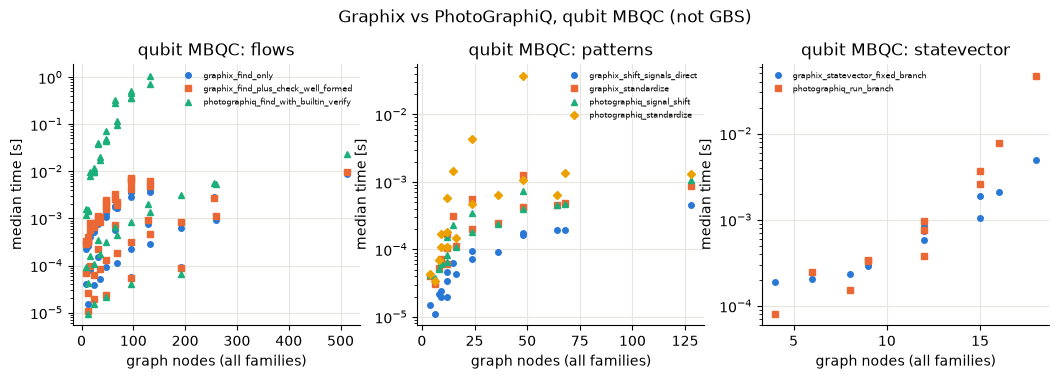

In [10]:
files = sorted(
    glob.glob(str(ROOT / "benchmarks" / "graphix" / "results" / "*.json")), key=os.path.getmtime
)
if not files:
    print("No Graphix benchmark JSON found in benchmarks/graphix/results/ - skipped.")
else:
    data = json.loads(Path(files[-1]).read_text(encoding="utf-8"))
    print("loaded", files[-1])
    print("scope:", data.get("scope"))
    # Rows carrying "nodes" and per-implementation {"median_s": ...} timings, one panel per section.
    sections = {
        k: v
        for k, v in data.items()
        if isinstance(v, list) and v and isinstance(v[0], dict) and "nodes" in v[0]
    }
    if not sections:
        print("No (nodes, median_s) records recognised; top-level keys:", list(data))
    else:
        fig, axes = common.new_axes(len(sections), width=4.2)
        for ax, (section, rows) in zip(axes, sections.items()):
            impls = sorted(
                {k for r in rows for k, v in r.items() if isinstance(v, dict) and "median_s" in v}
            )
            for i, impl in enumerate(impls):
                pts = [
                    (r["nodes"], r[impl]["median_s"]) for r in rows if isinstance(r.get(impl), dict)
                ]
                st = common.series_style(i)
                ax.plot(
                    *zip(*pts), ls="none", color=st["color"], marker=st["marker"], ms=4, label=impl
                )
            ax.set(
                yscale="log",
                xlabel="graph nodes (all families)",
                ylabel="median time [s]",
                title=f"qubit MBQC: {section}",
            )
            ax.legend(frameon=False, fontsize=6)
        fig.suptitle("Graphix vs PhotoGraphiQ, qubit MBQC (not GBS)", y=1.04)
        plt.show()

## 11 Runtime plots

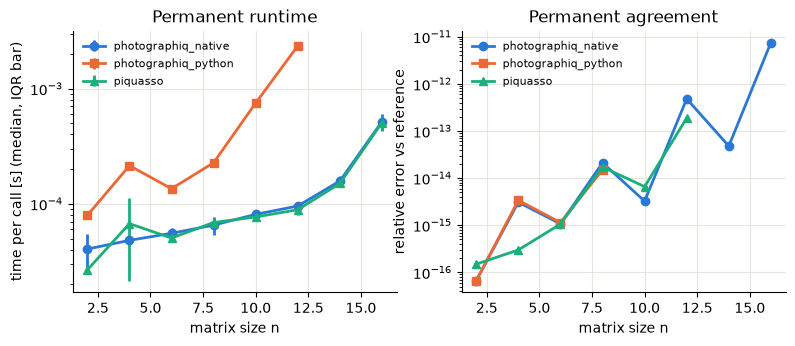

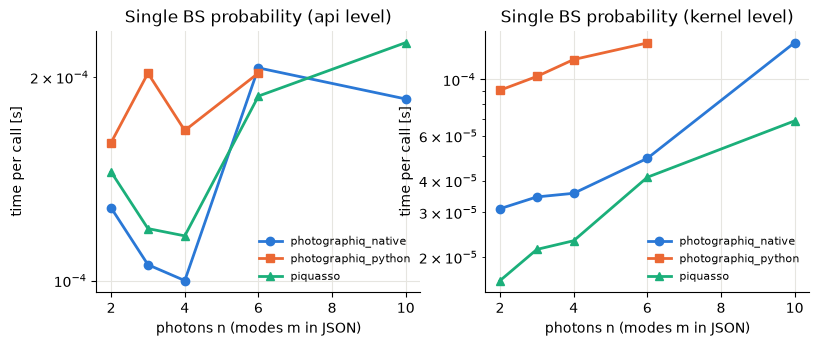

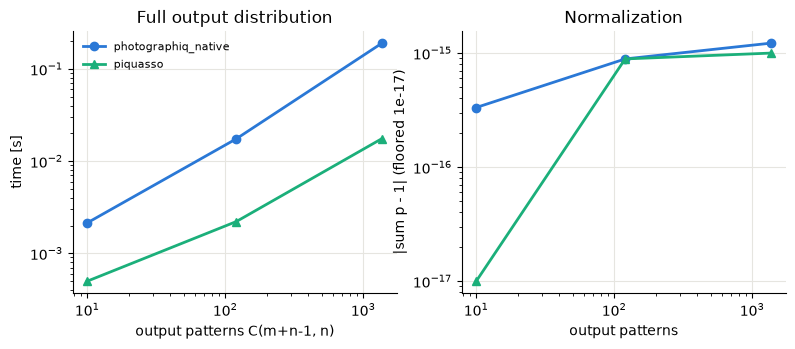

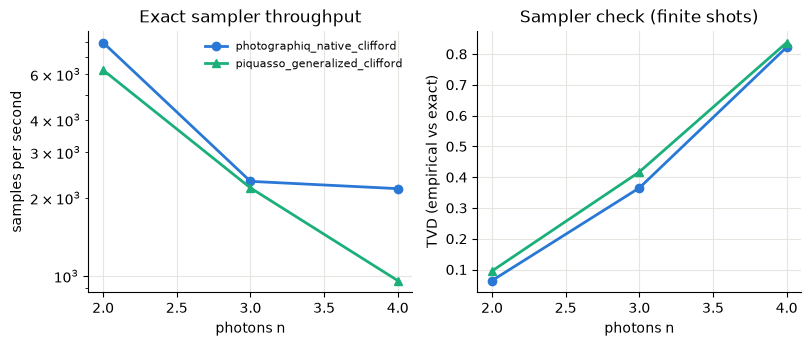

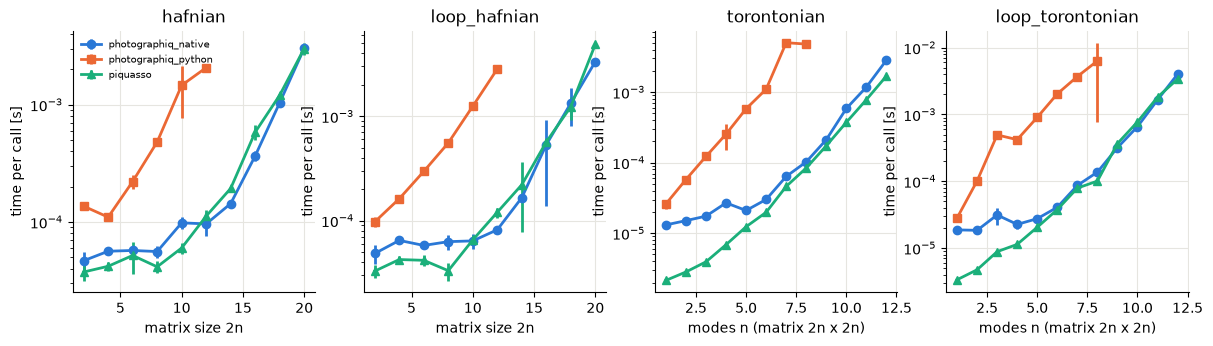

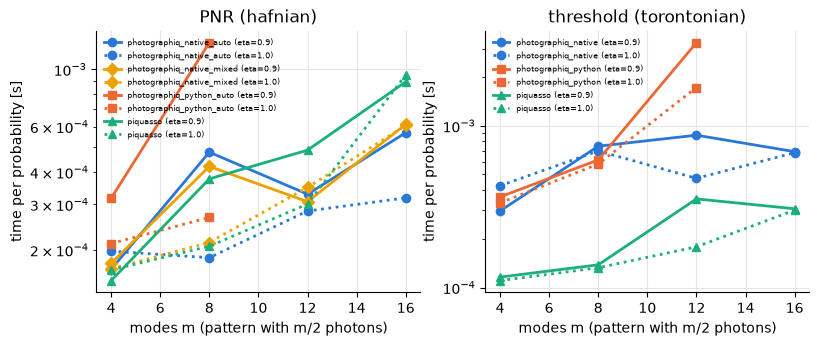

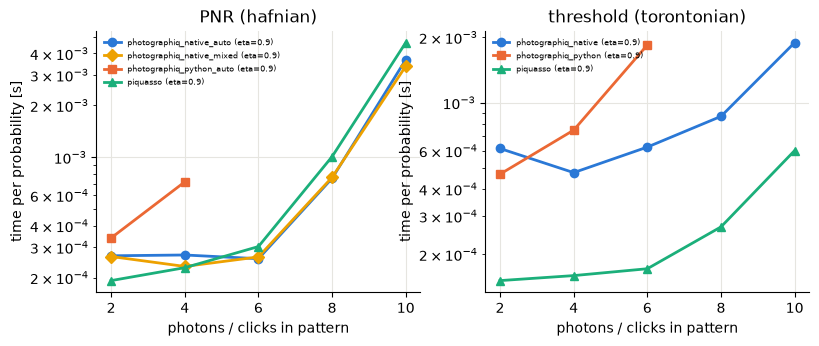

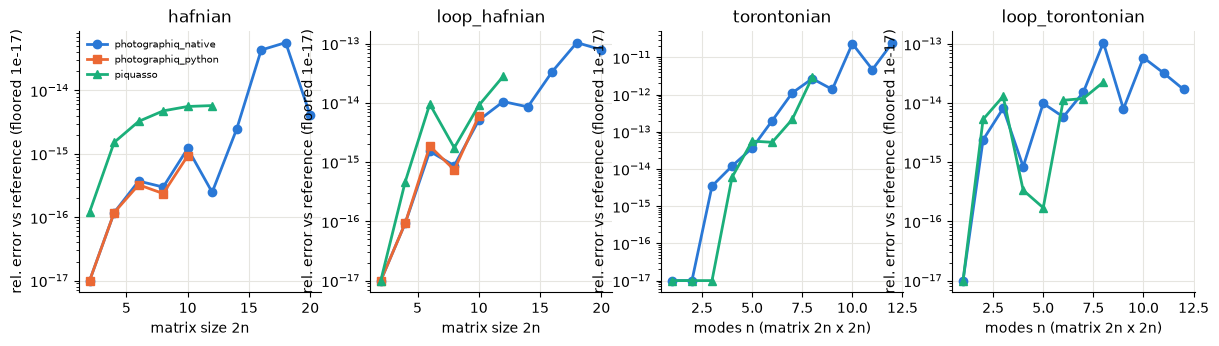

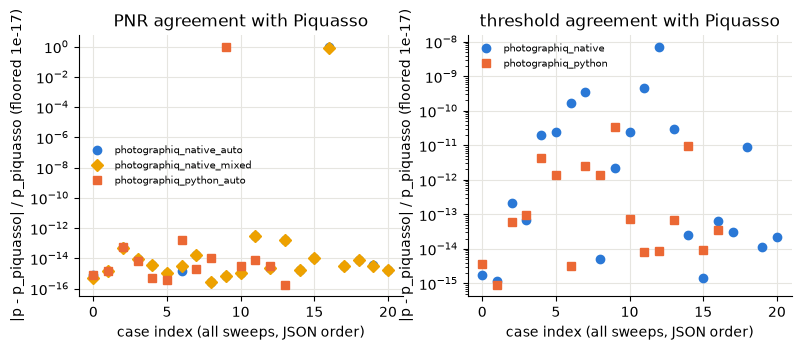

In [11]:
bs_figs = dict(bbs.plot(BS, OUT, save=False))
gbs_figs = dict(bgbs.plot(GBS, OUT, save=False))
for name in ("bs_permanent", "bs_probability_runtime", "bs_distribution", "bs_sampling"):
    display(bs_figs[name])
for name in (
    "gbs_matrix_functions_runtime",
    "gbs_runtime_vs_modes",
    "gbs_runtime_vs_photons",
    "gbs_matrix_functions_correctness",
    "gbs_correctness",
):
    display(gbs_figs[name])
plt.close("all")

## 12 Memory plots

`tracemalloc` peak of one call: it covers Python-level and NumPy allocations, **not**
memory allocated directly by C/C++ (PhotoGraphiQ native kernels, Piquasso's C++ permanent /
torontonian) or by numba-compiled code. Treat it as a lower bound for those implementations.

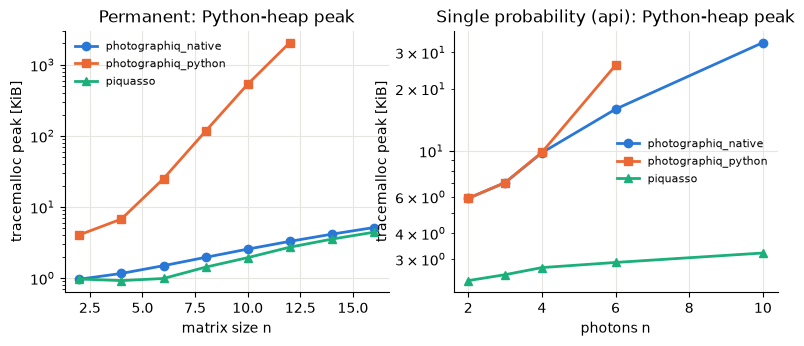

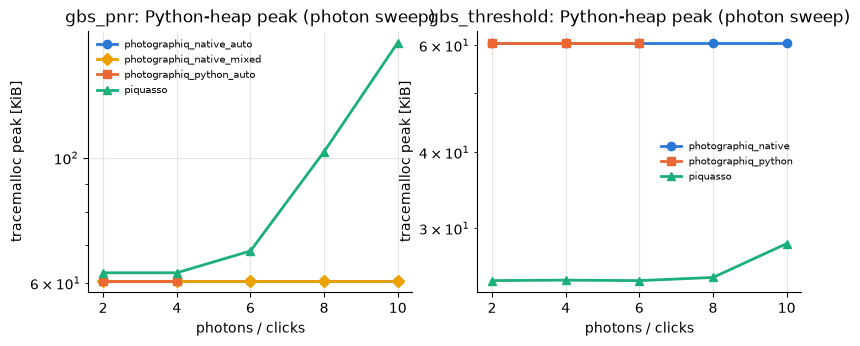

In [12]:
display(bs_figs["bs_memory"])
display(gbs_figs["gbs_memory"])
plt.close("all")

## 13 Scaling analysis

Fit $\log_2 t = a\,x + b$ over the larger half of the measured sizes. Expected exponents
(time doubling per unit of $x$): permanent (Ryser/Glynn) $\approx 1$ per row ($2^n$, times a
polynomial factor), hafnian $\approx 0.5$ per matrix dimension ($2^{d/2}$ power-trace terms),
torontonian $\approx 1$ per mode ($2^n$ subsets). Polynomial factors and fixed per-call
overheads bias small-size fits.

In [13]:
def slope(rows, task, impl, x="n", **match):
    pts = sorted(
        (r[x], r["median_s"])
        for r in rows
        if r["task"] == task
        and r["implementation"] == impl
        and all(r.get(k) == v for k, v in match.items())
    )
    pts = pts[len(pts) // 2 :]
    if len(pts) < 2:
        return None, None
    xs, ts = np.array(pts).T
    return np.polyfit(xs, np.log2(ts), 1)[0], (int(xs[0]), int(xs[-1]))


for rows, task, x, match in (
    (BS["results"], "permanent", "n", {}),
    (GBS["results"], "hafnian", "n", {}),
    (GBS["results"], "loop_hafnian", "n", {}),
    (GBS["results"], "torontonian", "n", {}),
    (GBS["results"], "gbs_pnr", "photons", {"sweep": "photons"}),
    (GBS["results"], "gbs_threshold", "photons", {"sweep": "photons"}),
):
    for impl in sorted({r["implementation"] for r in rows if r["task"] == task}):
        a, rng_ = slope(rows, task, impl, x, **match)
        if a is not None:
            print(f"{task:14s} {impl:32s} log2(t) slope {a:5.2f} per unit {x} over {x} in {rng_}")

permanent      photographiq_native              log2(t) slope  0.44 per unit n over n in (10, 16)
permanent      photographiq_python              log2(t) slope  0.84 per unit n over n in (8, 12)
permanent      piquasso                         log2(t) slope  0.45 per unit n over n in (10, 16)
hafnian        photographiq_native              log2(t) slope  0.64 per unit n over n in (12, 20)
hafnian        photographiq_python              log2(t) slope  0.53 per unit n over n in (8, 12)
hafnian        piquasso                         log2(t) slope  0.61 per unit n over n in (12, 20)
loop_hafnian   photographiq_native              log2(t) slope  0.69 per unit n over n in (12, 20)
loop_hafnian   photographiq_python              log2(t) slope  0.59 per unit n over n in (8, 12)
loop_hafnian   piquasso                         log2(t) slope  0.66 per unit n over n in (12, 20)
torontonian    photographiq_native              log2(t) slope  1.13 per unit n over n in (7, 12)
torontonian    photograp

## 14 Limitations and reproducibility metadata

* Timings are wall-clock on one machine, median of a few repeats with IQR and min; small
  sizes are dominated by Python call overhead and input validation, not by the kernels.
* PhotoGraphiQ native kernels use OpenMP (thread count printed below); Piquasso's permanent and
  torontonian are C++ and its hafnians numba; thread counts of those libraries are not
  controlled here, so cross-library runtime ratios are not single-core comparisons.
* `photographiq_native_precomputed` excludes the $O(m^3)$ setup and has no Piquasso
  counterpart; the auto PNR method uses the $N$-dimensional pure-state formula for lossless
  states while Piquasso always uses $2N$-dimensional hafnians (both give the same probability;
  the `mixed` rows are the algorithm-matched comparison).
* Piquasso's full-distribution call also covers patterns with fewer photons (exactly zero) and
  re-executes the program; the PhotoGraphiQ distribution loops over patterns in Python.
* Memory: `tracemalloc` misses native and numba allocations (lower bound only).
* Threshold probabilities with many clicks lose digits in double precision. Against a 50-digit
  reference (32 modes, 16 clicks) PhotoGraphiQ is off by 3e-3 to 8e-3 relative and Piquasso
  by 3e-4 (`benchmarks/README.md`). PhotoGraphiQ reports a rounding bound and warns
  (`ThresholdPrecisionWarning`); use `precision=` when the digits matter.
* No GPU code is involved. Graphix is a qubit-MBQC framework and is not benchmarked against GBS.

In [14]:
env = common.environment(seed={"boson_sampling": 7, "gbs": 11}, config=CONFIG)
print(json.dumps(env, indent=2, default=str))
print(f"notebook compute time: {time.perf_counter() - T0:.1f} s")

{
  "timestamp_utc": "2026-11-12T10:05:33+00:00",
  "cpu": "12th Gen Intel(R) Core(TM) i5-12450HX",
  "logical_cpus": 12,
  "platform": "Windows-11-10.0.26200-SP0",
  "python": "3.12.14",
  "packages": {
    "photographiq": "0.3.1",
    "piquasso": "8.0.1",
    "graphix": "0.4",
    "numpy": "2.5.3",
    "scipy": "1.18.1",
    "numba": "0.67.0"
  },
  "native_components": [
    "gaussian",
    "fock",
    "sampling"
  ],
  "native_build": {
    "compiler": "MSVC 19.50.35729.0",
    "build_type": "Release",
    "cxx_standard": 202002,
    "openmp": true,
    "eigen": "3.4.0",
    "hbar": 2.0
  },
  "native_sampling_max_threads": 12,
  "numba_num_threads": 12,
  "env_threads": {
    "OMP_NUM_THREADS": null,
    "OPENBLAS_NUM_THREADS": null,
    "MKL_NUM_THREADS": null,
    "NUMBA_NUM_THREADS": null
  },
  "precision": "complex128 / float64 throughout",
  "seed": {
    "boson_sampling": 7,
    "gbs": 11
  },
  "git": {
    "commit": "f30321fd09140b310c3fb53e02a9b503e756855f",
    "dirty":